In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

In [2]:
df = pd.read_csv("classification_escalation.csv")

In [3]:
print(df.shape)

(900, 6)


In [4]:
display(df.head())

,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB


In [6]:
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


In [7]:
df.isnull().sum()

complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

In [8]:
(df.isnull().sum() / len(df)) * 100

complexity_score          0.000000
team_experience_years     3.444444
priority                  2.000000
channel                   0.000000
customer_tenure_months    2.444444
escalated                 0.000000
dtype: float64

In [9]:
X = df.drop("escalated", axis=1)
y = df["escalated"]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [11]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Training features: (675, 5)
Testing features: (225, 5)

Training target distribution:
escalated
0    0.792593
1    0.207407
Name: proportion, dtype: float64

Testing target distribution:
escalated
0    0.795556
1    0.204444
Name: proportion, dtype: float64


In [12]:
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

In [13]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [14]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [16]:
baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

In [17]:
baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['complexity_score','team_experience_years','priority','channel', 'customer_tenure_months']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [18]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [19]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['complexity_score','team_experience_years','priority','channel', 'customer_tenure_months']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [20]:
lda_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LinearDiscriminantAnalysis())
])

In [21]:
lda_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['complexity_score','team_experience_years','priority','channel', 'customer_tenure_months']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [22]:
knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=15))
])

In [23]:
knn_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['complexity_score','team_experience_years','priority','channel', 'customer_tenure_months']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [24]:
print("All models trained successfully!")

All models trained successfully!


In [25]:
baseline_pred = baseline.predict(X_test)

logistic_pred = logistic_model.predict(X_test)

lda_pred = lda_model.predict(X_test)

knn_pred = knn_model.predict(X_test)

In [26]:
def evaluate_model(name, model, predictions):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    }

In [27]:
results = [
    evaluate_model("Majority Baseline", baseline, baseline_pred),
    evaluate_model("Logistic Regression", logistic_model, logistic_pred),
    evaluate_model("LDA", lda_model, lda_pred),
    evaluate_model("k-NN (k=15)", knn_model, knn_pred)
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,LDA,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


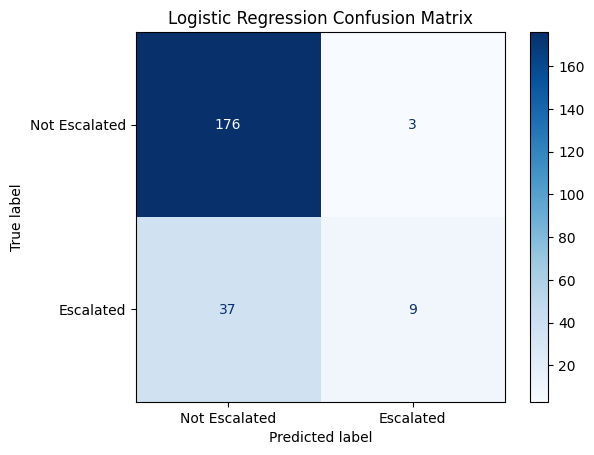

In [28]:
cm = confusion_matrix(y_test, logistic_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated", "Escalated"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

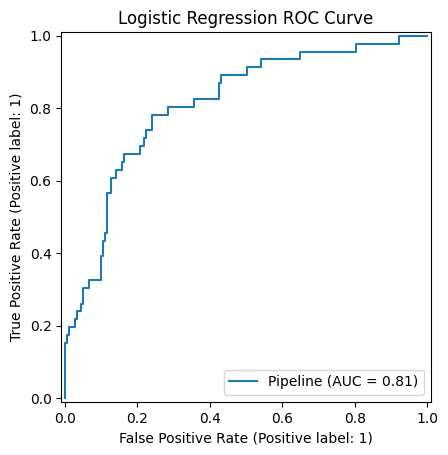

In [29]:
RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test
)

plt.title("Logistic Regression ROC Curve")
plt.show()

In [30]:
y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [31]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

In [32]:
threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test, y_pred_threshold, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred_threshold, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred_threshold, zero_division=0
    )

    cost = 5 * fn + fp

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FP": fp,
        "FN": fn,
        "Cost": cost
    })

In [33]:
y_pred_threshold = (y_prob >= threshold).astype(int)

In [34]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_threshold,
    labels=[0, 1]
).ravel()

In [35]:
threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(y_test, y_pred_threshold, zero_division=0)
    recall = recall_score(y_test, y_pred_threshold, zero_division=0)
    f1 = f1_score(y_test, y_pred_threshold, zero_division=0)

    cost = 5 * fn + fp

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FP": fp,
        "FN": fn,
        "Cost": cost
    })

In [36]:
threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230


In [41]:
best = threshold_df.loc[[threshold_df["Cost"].idxmin()]]
display(best.round(4))

,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98


Threshold 0.20 minimises the cost 5×FN + FP (cost = 98, vs 188 at the default 0.50). Lowering the threshold trades 45 more false alarms for 27 fewer missed escalations, which pays off because a miss costs five times as much. This estimate is optimistic: the threshold was chosen on the test set (only 46 escalations), and 0.20 is the lowest value tried. Theory suggests 1/(1+5) ≈ 0.167, so the true optimum may be lower. The threshold should be re-tuned with cross-validation on the training set.

In [37]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_search = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

knn_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': [5, 9, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inf

In [38]:
print("Best k:", knn_search.best_params_)
print("Best Cross-Validation F1:", knn_search.best_score_)

cv_results = pd.DataFrame(knn_search.cv_results_)
display(
    cv_results[["param_classifier__n_neighbors", "mean_test_score", "std_test_score"]]
    .round(4)
)

Best k: {'classifier__n_neighbors': 5}
Best Cross-Validation F1: 0.24329611908559276


,param_classifier__n_neighbors,mean_test_score,std_test_score
0,5,0.2433,0.0946
1,9,0.1976,0.0652
2,15,0.1596,0.0655
3,21,0.1458,0.0564
4,31,0.1122,0.0397


In [39]:
best_knn = knn_search.best_estimator_

best_knn_pred = best_knn.predict(X_test)

print("Best k-NN Test Results")
print("Accuracy:", accuracy_score(y_test, best_knn_pred))
print("Precision:", precision_score(y_test, best_knn_pred, zero_division=0))
print("Recall:", recall_score(y_test, best_knn_pred, zero_division=0))
print("F1:", f1_score(y_test, best_knn_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(
    y_test, best_knn.predict_proba(X_test)[:, 1]
))

Best k-NN Test Results
Accuracy: 0.7911111111111111
Precision: 0.46153846153846156
Recall: 0.13043478260869565
F1: 0.2033898305084746
ROC-AUC: 0.6306776779208161


Questions to answer
● Why is accuracy alone potentially misleading?
The majority baseline scores 79.6% accuracy while catching zero escalations. Logistic regression scores 82.2%, only 2.7 points better, yet its confusion matrix shows it misses 37 of the 46 escalated tickets. Because 80% of tickets are not escalated, a model can look accurate while doing almost nothing useful.
● Which classifier has the strongest recall? Which has the strongest precision/F1?
At the default 0.5 threshold, logistic regression and LDA tie on every metric except ROC-AUC: recall 0.196, precision 0.75 and F1 0.310. Logistic regression is slightly ahead on ROC-AUC (0.811 vs 0.809). k-NN is weaker on everything. Tuned to k=5, its test F1 rises to 0.203, but its ROC-AUC falls to 0.631. With only 5 neighbours, its probability scores are coarse.
● What changes when the threshold is lowered?
The model flags more tickets as escalations. From 0.50 down to 0.20:
•	Recall rises from 0.20 to 0.78.
•	Precision falls from 0.75 to 0.43.
•	False negatives drop from 37 to 10.
•	False positives rise from 3 to 48.
F1 is highest at 0.30 (0.577), but cost is lowest at 0.20. So the metric you optimise changes which threshold you pick.

● Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be optimistic if used repeatedly for tuning?
0.20, with a cost of 98, against 188 at the default 0.50.the threshold was chosen on the test set, so the test set is no longer an unbiased judge. It has only 46 positives, and each missed escalation adds 5 to the cost, so a few tickets can change the winner. Re-tuning on the same test set again and again fits its noise. 0.20 is the lowest value in the grid, so the true best may be lower .

● Explain prior, likelihood, posterior, and evidence using the ticket scenario.

P(escalated) ≈ 0.21: the share of tickets that escalate, before looking at any features.
Likelihood, p(x | escalated): how typical this ticket's features (complexity, team experience, priority and so on) are among escalated tickets, compared with p(x | not escalated) among the rest.
Evidence, p(x) = p(x | esc)·P(esc) + p(x | not)·P(not): how common this feature pattern is overall. It rescales the result so it is a proper probability.
Posterior, P(escalated | x) = likelihood × prior / evidence: the updated probability for this particular ticket. LDA builds it this way, assuming Gaussian likelihoods. Logistic regression estimates it directly.

● With posterior P(escalated|x)=0.30, false-positive cost 1 and false-negative cost 5, compare
the expected cost of escalating and not escalating. Derive the cost-sensitive threshold.
Escalate: you are wrong only if the ticket wasn't going to escalate. Cost = 0.70 × 1 = 0.70.
Don't escalate: you are wrong only if it was going to escalate. Cost = 0.30 × 5 = 1.50. So escalate.
Threshold: escalate when p × 5 > (1 − p) × 1, which gives p > 1/(1+5) ≈ 0.167. In general it is C_FP / (C_FP + C_FN). 

● Which model would you recommend for deployment, and what further checks are required?

Logistic regression with a threshold of about 0.17–0.20. It has the best ROC-AUC, gives interpretable coefficients and produces usable probabilities.
 Before deployment, check:
•	that the threshold holds up under cross-validation;
•	that the probabilities are calibrated (actual escalation rates match predicted ones);
•	error rates across channel and priority groups;
•	that the 5:1 cost ratio reflects real business costs;
•	how the model is monitored for drift over time;
•	that a person reviews flagged tickets rather than the model acting alone.


I recommend deploying logistic regression with a decision threshold of about 0.20 instead of the default 0.50, subject to the checks below.
Logistic regression and LDA performed almost identically on the test set (accuracy 0.822, precision 0.75, recall 0.196, F1 0.310 at the default threshold). Logistic regression had the higher ROC-AUC (0.811 vs 0.809) and makes fewer assumptions than LDA, which assumes normally distributed features with a shared covariance. It is also easy to explain: each coefficient shows how a feature changes the odds of escalation. k-NN was clearly weaker (ROC-AUC 0.705 at k=15). Tuning k by cross-validated F1 selected k=5, but its test ROC-AUC fell to 0.631. The majority baseline reached 79.6% accuracy while catching no escalations, which shows why accuracy cannot guide this decision. Missing an escalation (a false negative) is assumed to cost five times as much as an unnecessary flag (a false positive). At the default threshold the model missed 37 of 46 escalated tickets, for a cost of 188. Lowering the threshold to 0.20 caught 36 of 46 (recall 0.78) at the price of 48 false alarms, cutting the cost to 98. This agrees with decision theory: with costs of 1 and 5, a ticket should be flagged whenever its predicted probability exceeds 1/(1+5), about 0.17. The trade-off is workload: at 0.20 the model flags 84 of 225 test tickets (37%), so the team reviewing flags needs the capacity to handle them.I chose the threshold on the test set, which contains only 46 escalations, so the cost of 98 is an optimistic estimate. I should re-select the threshold with cross-validation on the training data and confirm it on new data. The dataset is synthetic, small (900 tickets) and has only five predictors, so discrimination is moderate (AUC 0.81). The 5:1 cost ratio is illustrative and should be replaced with real business costs. Missing values were filled with the median or most frequent value, which may hide information about why data are missing. I have not checked probability calibration, yet the cost-based threshold assumes the probabilities are reliable.
I recommend that the model support my judgment rather than replace it: a flag should prompt early attention, not automatic action. I would compare error rates across channels and priority levels so that no customer group is consistently overlooked. Because team experience is a predictor, I would use predictions to route tickets, not to judge staff. Finally, I would monitor performance after deployment for drift in escalation rates and feature patterns, with retraining when it declines.
